# Laboratorio 5A · Del perceptrón a la red profunda

**MantenIA**, la empresa ficticia de mantenimiento industrial del curso, quiere anticipar las fallas de una máquina de fresado a partir de las lecturas de sus sensores: la temperatura del aire y del proceso, la velocidad de giro, el torque y el desgaste de la herramienta. Si sabe que la máquina va a fallar, puede parar antes y cambiar la herramienta.

Usted entrenará con PyTorch, la librería de redes neuronales más usada, un **perceptrón multicapa**: una **red neuronal** que aprende sus **pesos** con 5000 registros etiquetados. No escribirá código: cambiará las capas, las neuronas, la **tasa de aprendizaje**, las épocas y el **dropout**, y leerá las **curvas de aprendizaje** como un tablero.

En este laboratorio usted:
* Entrenará en PyTorch un perceptrón multicapa que predice si una máquina fallará.
* Verá qué hace la tasa de aprendizaje: llegar al fondo del valle, no llegar o rebotar.
* Provocará el **sobreajuste** y lo frenará con dropout y **parada temprana**.
* Comparará redes de distinta profundidad y anchura en fallas detectadas, falsas alarmas y tiempo.
* Descubrirá lo que esconde la exactitud cuando las fallas son pocas.

| | |
| :--- | :--- |
| **Resultado de aprendizaje** | RA6: explicar y aplicar redes neuronales y aprendizaje profundo. |
| **Tiempo** | 60 minutos en clase (secciones 0 a 6) y hasta 30 en casa (la sección 7, los análisis ✏️ y la 8). En clase, escriba cada análisis en una frase. |
| **Modalidad** | En parejas. **No se escribe código:** se cambian números en las celdas marcadas con ✏️. |
| **Antes de clase** | Ejecute en casa la primera celda: instala `torch` si falta, unos 130 MB. Si ya preparó el Laboratorio 4B, no descarga nada. |
| **Entrega** | Este notebook ejecutado y el archivo `resultados_5A.csv`, al inicio de la semana 4 del curso (sección 8). |

## Contenido

* [Antes de empezar](#0) · *en clase, 5 min*
* [1 - El caso: los registros de la máquina](#1) · *en clase, 5 min*
* [2 - La primera red](#2) · *en clase, 13 min*
* [3 - La tasa de aprendizaje](#3) · *en clase, 10 min*
* [4 - Memorizar no es aprender](#4) · *en clase, 5 min*
* [5 - Dos frenos: dropout y parada temprana](#5) · *en clase, 10 min*
* [6 - Profundidad y anchura](#6) · *en clase, 9 min*
* [7 - Para casa: la retropropagación, la prueba y un puente](#7) · *para casa, 20 min*
* [8 - Entrega y criterios](#8) · *para casa, 5 min*
* [Conclusión](#conclusion) · [Referencias](#referencias)

<details>
<summary><b>💡 Otra forma de navegar: el panel Esquema de VS Code</b> (clic para desplegar)</summary>

VS Code lista todos los títulos de este notebook en el panel **Esquema** (*Outline*), dentro del Explorador de la barra lateral izquierda. Al hacer clic en un título, el notebook salta a esa sección.

</details>

<a id='0'></a>
## Antes de empezar

Ejecute las celdas **en orden**. Solo se editan las celdas marcadas con ✏️: en ellas se cambian números, nunca el resto del código.

<details>
<summary><b>Cómo usar este notebook en VS Code</b> (si lo necesita)</summary>

1. Con **Archivo › Abrir carpeta**, abra la carpeta del curso, la que contiene el entorno `.venv`.
2. Abra este notebook y, en **Seleccionar kernel** (arriba a la derecha), elija el entorno `.venv` del curso.
3. Ejecute cada celda con **Shift + Enter** o con el botón ▷ de su izquierda.
4. Para editar una celda de texto, como las de análisis, haga doble clic sobre ella; para verla de nuevo, **Shift + Enter**.
5. Si algo falla, lea el mensaje: los módulos de apoyo explican en español qué revisar, en una caja roja. Un `SyntaxError`, en inglés, quiere decir que algo de lo que escribió en la celda está mal formado: revise las comillas, las comas, los dos puntos y los corchetes. Si el problema persiste, use **Reiniciar** y luego **Ejecutar todo**.

</details>

<details>
<summary><b>Respaldo: trabajar en Google Colab</b> (por ejemplo, en un Mac con procesador Intel)</summary>

En un Mac con procesador Intel no hay `torch` para Python 3.13, y la red no corre en VS Code. Use Colab:
1. Pida al docente el archivo `lab_5A_red_profunda.zip` y abra este notebook en [Colab](https://colab.research.google.com/) con **Archivo › Subir notebook**.
2. Suba el .zip a la carpeta `/content` en el panel **Archivos** de Colab.
3. Ejecute la celda siguiente: descomprime la carpeta y usa el `torch` que Colab ya trae.

</details>

<details>
<summary><b>Glosario breve</b>, por si una palabra no le resulta familiar</summary>

* **Neurona artificial:** multiplica cada entrada por un peso, suma los resultados con un sesgo y pasa la suma por una activación.
* **Perceptrón multicapa:** una red de neuronas en capas, en la que cada neurona recibe todas las salidas de la capa anterior.
* **PyTorch:** la librería de Python con que se arman y entrenan las redes de este laboratorio.
* **Peso y sesgo:** los números que la red aprende. Se llaman, juntos, **parámetros**.
* **Capa oculta:** un grupo de neuronas entre las entradas y la salida.
* **Activación:** la función que transforma la suma de una neurona. La **ReLU** deja pasar los valores positivos y anula los negativos; la **sigmoide** da un número entre 0 y 1.
* **Pérdida:** un número que mide cuánto se equivoca la red; entrenar es bajarlo.
* **Gradiente:** la pendiente de la pérdida para cada peso: hacia dónde sube y cuánto.
* **Tasa de aprendizaje:** el tamaño de cada paso cuesta abajo.
* **Minilote y época:** cada paso usa un minilote de 400 registros; una época es una pasada por todos los de entrenamiento.
* **Entrenamiento, validación y prueba:** los registros con que la red aprende, con que se comparan configuraciones y con que se mide el resultado final.
* **Sobreajuste:** la red se aprende de memoria los registros de entrenamiento y falla en los nuevos.
* **Dropout:** apagar al azar una fracción de las neuronas en cada paso del entrenamiento, para que la red memorice menos (sección 5).
* **Parada temprana:** detener el entrenamiento cuando la pérdida de validación deja de mejorar y quedarse con la mejor red (sección 5).
* **Semilla:** el número con que arranca el azar del computador. Fijarla hace que los pesos iniciales y el orden de los minilotes se repitan en cada ejecución.
* **Exactitud:** la fracción de registros bien clasificados.
* **Falsa alarma:** la red dice «falla» y la máquina no falló.
* **CPU:** el procesador general del computador. La red se entrena en él, sin tarjeta gráfica.

</details>

* Ejecute la siguiente celda para preparar el entorno: comprueba Python e instala lo que falte de `requirements.txt`.

In [ ]:
# Preparar el entorno: comprobar Python e instalar lo que falte de requirements.txt
import os, pathlib, sys, zipfile
if "google.colab" in sys.modules and not pathlib.Path("entorno.py").exists():
    # Respaldo en Colab: descomprimir la carpeta del laboratorio que usted subió como .zip
    zipfile.ZipFile("/content/lab_5A_red_profunda.zip").extractall("/content")
    os.chdir("/content/lab_5A_red_profunda")
import entorno
entorno.preparar(en_colab_aceptar=("torch",))

El laboratorio usa tres módulos de apoyo, en la misma carpeta del notebook.

<details>
<summary><b>Qué hace cada módulo</b> (clic para desplegar)</summary>

* `red_fallas` lee los datos, arma y entrena la red, compara configuraciones y anota cada red en `resultados_5A.csv`.
* `graficas` dibuja las curvas de aprendizaje y la matriz de confusión.
* `presentacion` muestra tablas y mensajes en cajas de color.

</details>

* Ejecute la siguiente celda para importar los módulos.

In [ ]:
# Importar los módulos de apoyo del laboratorio
import red_fallas as rf
import presentacion as p

<a id='1'></a>
## 1 - El caso: los registros de la máquina

El **AI4I 2020** (Matzka, 2020) tiene 10 000 registros de una máquina de fresado. UCI, el repositorio que lo publica, lo describe como «a synthetic dataset that reflects real predictive maintenance data encountered in industry»: es **sintético**, generado para parecerse a datos reales. Sirve para aprender; sus cifras no son las de una planta real.

| Columna | Qué mide | ¿La usa la red? |
| :--- | :--- | :--- |
| Tipo | La calidad del producto: L (baja), M (media) o H (alta) | Sí, como tres columnas de 0 y 1 |
| Temperatura del aire y del proceso | En kelvin: 300 K son unos 27 °C | Sí |
| Velocidad de giro | Revoluciones por minuto | Sí |
| Torque | La fuerza de giro, en newton-metro | Sí |
| Desgaste de la herramienta | Minutos de uso | Sí |
| `Machine failure` | 1 si la máquina falló | Es la respuesta |
| `UDI`, `Product ID` | El número de fila y el código de la pieza | No: no son lecturas |
| `TWF`, `HDF`, `PWF`, `OSF`, `RNF` | El modo de cada falla | No: contienen la respuesta |

Son **8 entradas**. Las columnas de los modos de falla se excluyen porque producirían una **fuga de información**: con ellas, la red acertaría sin aprender nada de los sensores, y en la operación esas columnas solo existen después de la falla.

* Ejecute la siguiente celda para leer los registros.

In [ ]:
# Leer el AI4I 2020: algunos registros y la proporción de fallas
datos = rf.cargar_datos()

**Estandarizar.** Las entradas vienen en escalas muy distintas: unos 300 kelvin, unas 1500 rpm, unos 40 Nm. Antes de entrar a la red, a cada una se le resta su promedio y se divide por su desviación estándar, para que todas queden en escalas comparables. El notebook lo hace solo.

**Tres partes.** La red aprende con los registros de **entrenamiento**. Con los de **validación**, que no usa para aprender, se comparan configuraciones y se decide cuándo parar. Los de **prueba** se miran **una sola vez**, al final: si se usaran para elegir, el resultado sería optimista.

* Ejecute la siguiente celda para ver las tres partes y la línea base.

In [ ]:
# Registros y fallas de cada parte, y la exactitud de responder siempre «no falla»
rf.mostrar_separacion(datos)

**Análisis.** Solo 3 de cada 100 registros son fallas: es un conjunto **desbalanceado**. Una regla que nunca avisa acierta casi el 97 % y no sirve para nada. Por eso, en todo el laboratorio se mira, además de la exactitud, cuántas fallas detecta la red y cuántas falsas alarmas da.

<a id='2'></a>
## 2 - La primera red

Una **neurona** recibe las entradas, multiplica cada una por un **peso**, suma los resultados con un **sesgo** y pasa la suma por una **activación**. Es como un puntaje de riesgo en una hoja de cálculo, con una diferencia: los pesos no los escribe nadie, la red los aprende. La activación **ReLU** deja pasar los valores positivos y anula los negativos; la **sigmoide** convierte la salida en un número entre 0 y 1, la probabilidad de falla. Muchas neuronas en **capas**, cada una conectada con todas las de la capa anterior, forman un **perceptrón multicapa**. El perceptrón de Rosenblatt (1958) era una sola neurona.

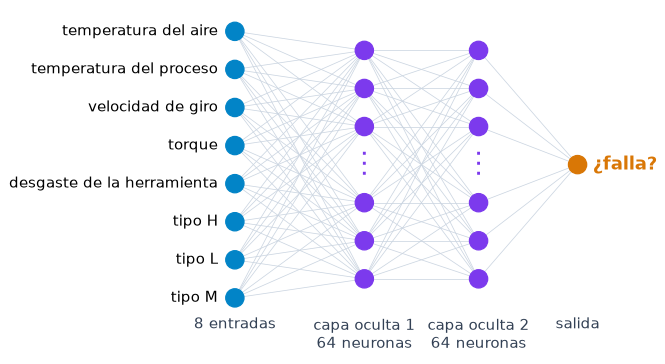

**Cómo aprende.** La **pérdida** mide cuánto se equivoca la red. Entrenar es bajar un valle con niebla: en cada paso se mira la pendiente bajo los pies, el **gradiente**, y se baja un poco. El tamaño del paso es la **tasa de aprendizaje**. Cada paso usa un **minilote** de 400 registros, y una **época** es una pasada por los 5000 de entrenamiento. La **retropropagación** reparte la culpa del error entre todos los pesos, de la salida hacia atrás, y PyTorch la calcula solo: nadie deriva nada.

<details>
<summary><b>Para profundizar:</b> la pérdida, Adam y la diferenciación automática</summary>

* La pérdida de este laboratorio es la **entropía cruzada**, que castiga más cuanto más segura estaba la red de una respuesta equivocada. En PyTorch, `BCEWithLogitsLoss` la calcula y aplica la sigmoide al mismo tiempo; por eso la sigmoide no aparece en la lista de capas.
* El notebook usa **Adam** (Kingma y Ba, 2015), la variante del descenso de gradiente más usada: ajusta el paso de cada peso según su historia. La tasa de aprendizaje sigue siendo el tamaño base del paso.
* La **diferenciación automática** registra cada operación del cálculo hacia adelante y aplica la regla de la cadena hacia atrás. La sección 7.1, para casa, comprueba que acierta.

</details>

**Desglose del experimento.** La celda trae la red de la figura: dos capas ocultas de 64 neuronas, dropout de 0.3 (sección 5), tasa de aprendizaje 0.001 y 60 épocas. Muestra la red en PyTorch, donde cada `nn.Linear` es una capa de neuronas con sus pesos y sesgos, y sus **curvas de aprendizaje**: la pérdida en entrenamiento, en cian, y en validación, en ámbar, al final de cada época. En clase, ejecútela tal como está: las secciones 3 y 4 usan estos valores. En casa puede volver a ella y probar otros.

* Ejecute la siguiente celda para entrenar la primera red. Tarda menos de un segundo.

In [ ]:
# ✏️ La primera red: las neuronas de cada capa oculta, el dropout, la tasa de aprendizaje y las épocas
CAPAS = [64, 64]
DROPOUT = 0.3
TASA = 0.001
EPOCAS = 60
red_1 = rf.entrenar(datos, CAPAS, DROPOUT, TASA, EPOCAS, nombre="primera red")

**Cómo leer las curvas.** Si las dos bajan juntas, la red aprende algo que también sirve para los registros que no vio; si la de validación sube mientras la otra baja, memoriza (sección 4). Que la de validación quede un poco abajo no es un error: en validación hay algo menos de fallas, que son los casos difíciles.

La **matriz de confusión** cruza lo que pasó de verdad con lo que dijo la red, en los 3000 registros de validación. La red dice «falla» cuando su probabilidad de falla supera 0,5.

* Ejecute la siguiente celda para ver la matriz y compararla con la línea base.

In [ ]:
# La matriz de confusión de la primera red en validación
rf.matriz(red_1, datos)

**Análisis.** Compare la exactitud con la línea base: una diferencia de décimas puede esconder que la red ve pocas fallas. En mantenimiento importan dos casillas: las fallas que no vio, que paran la planta sin aviso, y las falsas alarmas, que paran la máquina sin necesidad. Cuántas alarmas tolerar depende del costo de cada error, tema de la Unidad 6.

**✏️ Su análisis (sección 2).** *En clase, responda solo la primera pregunta, en una frase; la otra, en casa. ¿Cuántas fallas detectó la red y cuántas falsas alarmas dio? Si a quien dirige el mantenimiento le mostraran solo la exactitud, ¿qué conclusión equivocada podría sacar?*

*Escriba aquí.*

<a id='3'></a>
## 3 - La tasa de aprendizaje

La tasa de aprendizaje es el tamaño del paso cuesta abajo. Con pasos muy pequeños, la red avanza tan despacio que no llega al fondo del valle en las épocas que tiene. Con pasos muy grandes, salta fuera del valle: la pérdida se dispara en los primeros pasos y la red queda atascada en una solución pobre. Entre los dos extremos está la tasa que baja bien.

**Desglose del experimento.** La celda entrena la misma red de la sección 2 con cada tasa de la lista `TASAS` y dibuja la pérdida de validación **después de cada paso**, para que se vean los saltos. La línea gris punteada es la pérdida de una «red» que responde siempre «no falla». La tabla da también la pérdida más alta en el camino: un número grande delata un salto. La lista ya trae 0.001; agregue una tasa muy pequeña, como 0.00001, y una muy grande, como 1.0. Los decimales van con punto: si aparece `SyntaxError: leading zeros…`, escribió una coma decimal.

<details>
<summary><b>Pista</b></summary>

Las tasas van separadas por comas y con punto decimal: `[0.00001, 0.001, 1.0]`. Python lee `0,001` como dos números, 0 y 001, y por eso protesta.

</details>

* Agregue a `TASAS` una tasa muy pequeña y una muy grande, y ejecute la celda.

In [ ]:
# ✏️ Las tasas de aprendizaje que se comparan: 0.001 ya está; agregue una muy pequeña y una muy grande
TASAS = [0.001]
tasas = rf.comparar_tasas(datos, TASAS, CAPAS, DROPOUT, EPOCAS)

**Análisis.** Busque tres formas: una curva que baja muy despacio y termina alta, una que baja rápido y se queda abajo, y una que salta al principio y se queda pegada en la línea gris. Pegarse a la línea gris significa que la red aprendió a decir siempre «no falla»: mire en la tabla cuántas fallas detecta.

**✏️ Su análisis (sección 3).** *Complete la tabla en clase; la pregunta, en casa.*

| Tasa | ¿Qué pasó? (no llega, llega, o salta y se atasca) |
| :--- | :--- |
| la pequeña: | |
| 0.001 | |
| la grande: | |

*¿Por qué la tasa más grande termina sin detectar fallas, si da los pasos más largos? Pista: después del salto, ¿cambia algo la curva? Una red que responde lo mismo a todos los registros tiene neuronas que dejaron de responder.*

<a id='4'></a>
## 4 - Memorizar no es aprender

Una red con muchos pesos y pocos registros puede aprenderse de memoria los registros de entrenamiento, con su ruido, en lugar de aprender lo que se repite. Eso es el **sobreajuste**. Se lee en las curvas como en un tablero: la pérdida de entrenamiento sigue bajando y la de validación, después de un mínimo, sube.

**Desglose del experimento.** La celda entrena una red sin dropout durante `EPOCAS_LARGO` épocas, con los primeros `REGISTROS` registros de entrenamiento y las capas de `CAPAS_GRANDE`. Con la configuración que trae, la red no memoriza. Provoque el sobreajuste: baje `REGISTROS` a 400, que tienen solo 8 fallas, y agrande la red a tres capas de 128 neuronas. La comprobación dice si las curvas se separaron.

* Cambie `REGISTROS` y `CAPAS_GRANDE`, y ejecute la celda.

In [ ]:
# ✏️ Provoque el sobreajuste: pocos registros de entrenamiento y una red grande, sin dropout
REGISTROS = 5000          # cuántos registros de entrenamiento usar (de 50 a 5000)
CAPAS_GRANDE = [64, 64]
EPOCAS_LARGO = 300
memoria = rf.entrenar(datos, CAPAS_GRANDE, 0.0, TASA, EPOCAS_LARGO, registros=REGISTROS, nombre="memorizar")
rf.comprobar_sobreajuste(memoria)

**Análisis.** La línea verde marca la época en que la pérdida de validación tocó su mínimo: hasta ahí, la red aprendía algo útil; desde ahí, memoriza. Si se hubiera quedado con la red de esa época, tendría una red mejor que la del final. Esa es la idea de la parada temprana.

<a id='5'></a>
## 5 - Dos frenos: dropout y parada temprana

**Dropout** (Srivastava et ál., 2014): en cada paso del entrenamiento se apaga al azar una fracción de las neuronas, por ejemplo el 30 %. Como ninguna puede contar con sus vecinas, la red reparte lo que aprende y memoriza menos. Al usar la red, todas trabajan.

**Parada temprana:** se vigila la pérdida de validación y, si no mejora durante una cantidad de épocas, la **paciencia**, se detiene el entrenamiento y se recupera la red de la mejor época.

**Desglose del experimento.** La celda toma la red de la sección 4 y la entrena otra vez con `DROPOUT_FRENO`, y luego con parada temprana para cada paciencia de `PACIENCIAS`. Escriba un dropout de 0.3 y dos paciencias, una corta y una larga, por ejemplo `[20, 50]`. La gráfica compara la validación sin frenos, punteada, con la validación con dropout, y marca dónde se detiene cada paciencia.

* Escriba el dropout y las paciencias, y ejecute la celda.

In [ ]:
# ✏️ Los frenos: la fracción de neuronas que se apagan (de 0 a 0.9) y las paciencias de la parada temprana
DROPOUT_FRENO = 0.0
PACIENCIAS = []           # épocas sin mejorar antes de parar; por ejemplo [20, 50]
frenos = rf.comparar_frenos(datos, memoria, DROPOUT_FRENO, PACIENCIAS)

**Análisis.** Compare la «pérdida de validación de esa red» con la fila de referencia: cuanto más baja, mejores probabilidades da la red, pero si apenas baja de la referencia, no aprendió a reconocer fallas. Una paciencia corta puede detenerse en un bache, un mínimo pasajero; una larga cuesta más épocas. Y con 400 registros y 8 fallas, un freno mejora la pérdida, pero no inventa los ejemplos que faltan.

**✏️ Su análisis (secciones 4 y 5).** *En clase, responda solo la primera pregunta, en una frase; las demás, en casa. ¿En qué época empezó a memorizar la red, qué fila de la tabla de frenos dejó la menor pérdida de validación, y cuántas fallas detecta esa red? ¿Por qué una paciencia corta puede detenerse demasiado pronto? ¿Qué cambiaría más el resultado: un freno o más registros?*

*Escriba aquí.*

<a id='6'></a>
## 6 - Profundidad y anchura

Una red es más **profunda** si tiene más capas ocultas, y más **ancha** si tiene más neuronas por capa. Las dos cosas aumentan los **parámetros**: la red puede representar relaciones más complejas, pero tarda más en entrenarse y memoriza con más facilidad. Más parámetros ayudan hasta cierto punto; después, la red tarda más sin detectar más fallas.

**Desglose del experimento.** Cada red de la lista `REDES` se entrena con los 5000 registros, dropout de 0.3, tasa 0.001 y `EPOCAS_REDES` épocas. La tabla compara su tamaño, su exactitud, las fallas que detecta, sus falsas alarmas y su tiempo de entrenamiento en su computador. La red `[64, 64]` es la de la sección 2, ahora con 100 épocas en vez de 60: también cuenta cuánto se entrena. La lista trae tres redes; agregue una suya, más ancha, más profunda o más pequeña, como `[256, 256, 256, 256]`.

<details>
<summary><b>Pista</b></summary>

Cada red va entre corchetes, seguida de una coma: `[256, 256, 256, 256],`. Si aparece `SyntaxError: unmatched ']'`, sobra un corchete; Python señala dónde se dio cuenta, que puede ser una línea después del corchete que sobra.

</details>

* Agregue una red a `REDES` y ejecute la celda. La más grande puede tardar unos segundos.

In [ ]:
# ✏️ Las redes que se comparan: cada lista es una red, con las neuronas de cada capa oculta
REDES = [
    [16],
    [64, 64],
    [128, 128, 128],
]
EPOCAS_REDES = 100
redes = rf.comparar_redes(datos, REDES, dropout=0.3, tasa=0.001, epocas=EPOCAS_REDES)

**Análisis.** Lea la tabla de arriba hacia abajo: ¿las fallas detectadas crecen con los parámetros, o se estancan? ¿Y el tiempo? Mire también las falsas alarmas: una red que detecta más fallas puede dar también más alarmas. Una diferencia de una o dos fallas entre redes no es concluyente, porque cambiaría con otra semilla. En la gráfica, la red que baja más rápido y más abajo aprende mejor; si una curva sube al final, esa red empieza a memorizar.

**✏️ Su análisis (sección 6).** *En clase, responda solo la primera pregunta, en una frase; la otra, en casa. ¿Qué red elegiría para MantenIA y por qué, con las cifras de la tabla? ¿Valió la pena la red más grande frente a su tiempo de entrenamiento?*

*Escriba aquí.*

<a id='7'></a>
## 7 - Para casa: la retropropagación, la prueba y un puente

<a id='7-1'></a>
### 7.1 - La retropropagación por dentro

PyTorch calcula la culpa de cada peso, su gradiente, con la retropropagación, en una sola pasada hacia atrás. ¿Cómo saber que acierta? Midiendo la pendiente: se mueve un peso un poquito hacia arriba y hacia abajo, se mide cuánto cambia la pérdida y se divide por lo que se movió. Es lenta, porque hay que repetirla para cada peso, pero no necesita derivar nada.

**Desglose del experimento.** La celda toma una red nueva de dos capas de 64 neuronas, sin dropout, y un minilote de 400 registros. Para cinco pesos muestra su valor, la culpa que calculó PyTorch y la pendiente medida. Luego da un paso del descenso de gradiente simple, con tasa 0.1: cada peso se mueve en contra de su culpa.

* Para casa: ejecute la celda y compare las dos columnas de culpa.

In [ ]:
# Un paso de entrenamiento por dentro: la culpa de cinco pesos, según PyTorch y medida a mano
rf.mirar_retropropagacion(datos)

**Análisis.** Si las columnas «culpa según PyTorch» y «pendiente medida» coinciden en sus primeras cifras, la diferenciación automática calculó bien. Un signo positivo dice que subir ese peso sube la pérdida; por eso el paso lo baja.

<a id='7-2'></a>
### 7.2 - La prueba, una sola vez

**Desglose del experimento.** Escriba la configuración que elegiría para MantenIA, con lo que aprendió en las secciones 3 a 6, y evalúe en prueba **una sola configuración**. La red se entrena con los 5000 registros, se vigila con validación y se evalúa en los 2000 de prueba, que nunca usó. Si quiere, use la parada temprana con `PACIENCIA_FINAL`; si no, escriba `None`. Cuando la haya elegido, cambie `EVALUAR_EN_PRUEBA` a `True`: así un «Ejecutar todo» anterior no la evalúa por adelantado. Volver a ejecutar la misma configuración no cuenta como mirar otra vez; cambiarla después de ver el resultado, sí.

* Para casa: escriba su configuración final, cambie `EVALUAR_EN_PRUEBA` a `True` y ejecute la celda.

In [ ]:
# ✏️ Para casa: la configuración elegida, que se evalúa una sola vez en los 2000 registros de prueba
CAPAS_FINAL = [64, 64]
DROPOUT_FINAL = 0.3
TASA_FINAL = 0.001
EPOCAS_FINAL = 60
PACIENCIA_FINAL = None    # o, por ejemplo, 20
EVALUAR_EN_PRUEBA = False # cámbielo a True cuando haya elegido
final = rf.evaluar_en_prueba(datos, CAPAS_FINAL, DROPOUT_FINAL, TASA_FINAL, EPOCAS_FINAL, PACIENCIA_FINAL, EVALUAR_EN_PRUEBA)

**Análisis.** Si la prueba se parece a la validación, su elección generaliza. Si es bastante peor, la configuración quedó ajustada a los registros de validación con que la eligió. Con 61 fallas en prueba, cada falla vale casi dos puntos de las detectadas: diferencias pequeñas no son concluyentes.

<a id='7-3'></a>
### 7.3 - Un puente con la Unidad 6

Un estudio de NeurIPS 2022 comparó redes profundas y modelos de árboles en conjuntos de datos de tabla, como este. Su conclusión: «los modelos de árboles siguen siendo el estado del arte con datos medianos (unas 10 000 muestras)» (Grinsztajn et ál., 2022). El AI4I tiene justo 10 000 registros. Trabajos más recientes discuten el resultado, pero la lección se mantiene: la red más profunda no siempre es la mejor opción. Los árboles de decisión son tema de la Unidad 6.

<a id='intentelo'></a>
### Inténtelo usted mismo

Todo se hace en las celdas ✏️ ya usadas:
* En la sección 4, suba `REGISTROS` a 1000 y a 2000: ¿desde cuántos registros deja de memorizar la red grande?
* En la sección 5, pruebe un dropout de 0.5: ¿frena más, o la red ya no aprende?
* En la sección 6, compare una red muy ancha, `[1024]`, con una muy profunda, `[16, 16, 16, 16, 16, 16]`.

**✏️ Su análisis (sección 7).** *Para casa. ¿Coincidieron la culpa según PyTorch y la pendiente medida? ¿Qué configuración llevó a prueba, y cuántas fallas detectó allí frente a validación? Para un caso de su organización con datos de tabla, ¿probaría primero una red o un modelo más simple, y por qué?*

*Escriba aquí.*

<a id='8'></a>
## 8 - Entrega y criterios

**Qué se entrega.** Este notebook ejecutado, con sus salidas visibles y las celdas ✏️ completas, y el archivo `resultados_5A.csv`, que anota cada red entrenada. Uno por pareja, por el canal del curso, al inicio de la semana 4.

**Resultados reproducibles.** Antes de terminar los análisis, ejecute el notebook completo (**Reiniciar** y **Ejecutar todo**) con sus configuraciones finales, y revíselos sobre esas salidas. Las redes usan semillas fijas, así que sus números se repiten en su computador; en otro pueden variar en los últimos decimales. Los tiempos cambian en cada ejecución: cítelos redondeados («menos de un segundo»).

| Criterio | Peso |
| :--- | :--- |
| Primera red y tasas de aprendizaje: la tabla de los tres comportamientos y la lectura de la matriz de confusión (secciones 2 y 3) | 25 % |
| Sobreajuste y frenos: las curvas separadas, el efecto del dropout y de la paciencia (secciones 4 y 5) | 30 % |
| Profundidad y anchura: una red propia y una elección justificada con la tabla (sección 6) | 20 % |
| La parte de casa: la retropropagación, la prueba única y el puente (sección 7), con análisis coherentes con las salidas | 25 % |

### ✏️ Declaración de uso de asistentes de IA

Declare si usaron asistentes de IA y para qué: por ejemplo, para entender un concepto o redactar un análisis.

* Escriba su declaración en la celda siguiente.

**✏️ Declaración de uso de IA.** *Escriba aquí su declaración.*

<a id='conclusion'></a>
## Conclusión

Usted entrenó un perceptrón multicapa sin escribir código y lo leyó como un tablero: la tasa de aprendizaje decide si la red llega al fondo del valle; las curvas que se separan delatan la memoria; el dropout y la parada temprana la frenan; y una red más grande no siempre detecta más. También vio que la exactitud engaña cuando las fallas son pocas.

En el **Laboratorio 5B**, la misma red recibe otra entrada: órdenes de trabajo escritas en español, convertidas en números por tres arquitecturas, una de ellas un transformer preentrenado. En el **trabajo independiente TI-1**, repetirá estos experimentos en TensorFlow Playground y los llevará a un problema de su organización; puede usar este notebook para ir más allá con datos reales. En el **proyecto del curso**, la guía de decisión de la charla de cierre le ayudará a elegir entre una red, un modelo preentrenado, un LLM o un modelo clásico.

<a id='referencias'></a>
## Referencias

* Matzka, S. (2020). Explainable artificial intelligence for predictive maintenance applications. *AI4I 2020*, IEEE, 69–74. [DOI](https://doi.org/10.1109/AI4I49448.2020.00023) · AI4I 2020 Predictive Maintenance Dataset, UCI Machine Learning Repository, CC BY 4.0. [DOI](https://doi.org/10.24432/C5HS5C)
* Rosenblatt, F. (1958). The perceptron: a probabilistic model for information storage and organization in the brain. *Psychological Review* 65(6), 386–408. [APA (archivo)](https://web.archive.org/web/20261019235840/https://psycnet.apa.org/doi/10.1037/h0042519)
* Rumelhart, D. E., Hinton, G. E. y Williams, R. J. (1986). Learning representations by back-propagating errors. *Nature* 323, 533–536. [DOI](https://doi.org/10.1038/323533a0)
* Kingma, D. P. y Ba, J. (2015). Adam: a method for stochastic optimization. *ICLR 2015*. [arXiv](https://arxiv.org/abs/1412.6980)
* Srivastava, N. et ál. (2014). Dropout: a simple way to prevent neural networks from overfitting. *JMLR* 15(56), 1929–1958. [JMLR](https://jmlr.org/papers/v15/srivastava14a.html)
* Grinsztajn, L., Oyallon, E. y Varoquaux, G. (2022). Why do tree-based models still outperform deep learning on typical tabular data? *NeurIPS* 35. [NeurIPS](https://proceedings.neurips.cc/paper_files/paper/2022/hash/0378c7692da36807bdec87ab043cdadc-Abstract-Datasets_and_Benchmarks.html)
* Prince, S. J. D. (2023). *Understanding Deep Learning*, cap. 3 a 7 y 9. MIT Press. [PDF oficial](https://udlbook.github.io/udlbook/)
* Zhang, A., Lipton, Z. C., Li, M. y Smola, A. J. (2023). *Dive into Deep Learning*, cap. 5 y 7. [d2l.ai](https://d2l.ai/)
* PyTorch: [`torch.nn`](https://docs.pytorch.org/docs/stable/nn.html), [`torch.optim.Adam`](https://docs.pytorch.org/docs/stable/generated/torch.optim.Adam.html) y [diferenciación automática](https://docs.pytorch.org/tutorials/beginner/basics/autogradqs_tutorial.html).